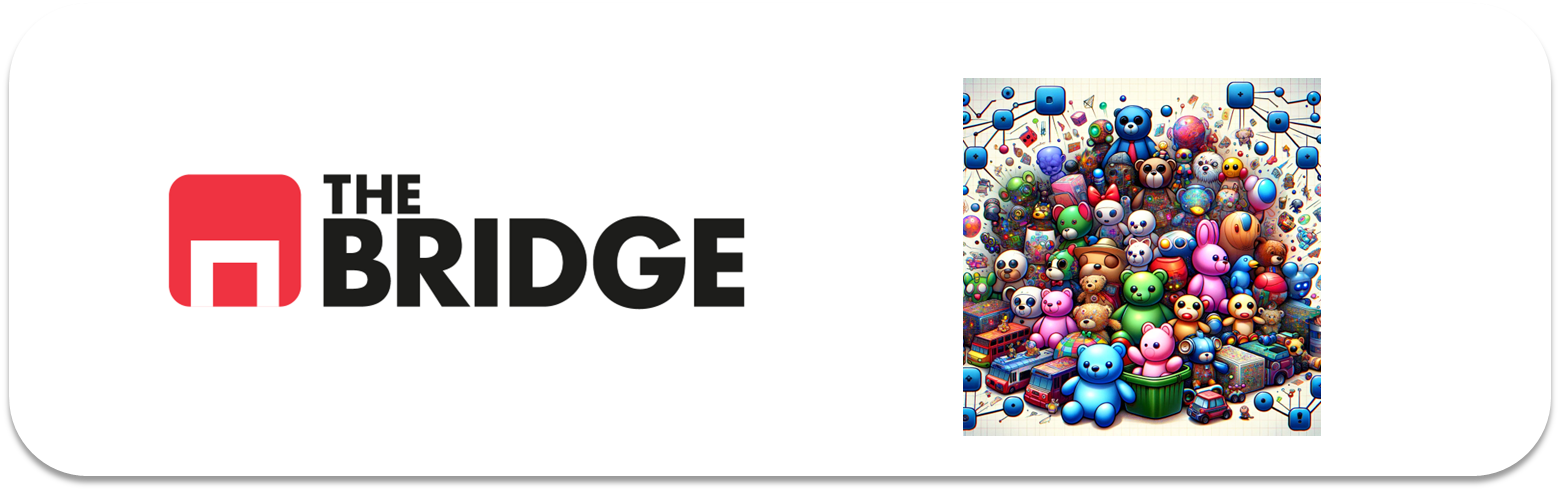

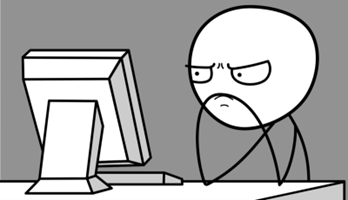

Para ejercitarte y afianzar lo aprendido sobre **K-Means**, completa los siguientes ejercicios. Recuerda que necesitarás los datos del directorio `data` de la unidad (`../data`).

Ya tienes las soluciones: intenta no mirarlas de primeras, pero no dejes de hacerlo cuando hayas terminado, por si te pudieran aportar.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,silhouette_samples
from sklearn.preprocessing import MinMaxScaler

# Ignoramos los avisos
import warnings
warnings.filterwarnings('ignore')

### Entendiendo el problema de negocio

En este notebook vamos a hacer un análisis de datos tirando de clusterizaciones para evaluar si existen grupos en nuestros productos, en este caso medicamentos, y posteriormente poder etiquetarlos. Poseemos información como rating, efectividad, efectos secundarios, entre otros.

### Ejercicio 1

Importa los datos, "../data/drugLibTrain_raw.tsv", que contiene un dataset con diferentes fármacos, sus efectos y ratings de los clientes de dichos fármacos. Realiza una inspección preliminar y quita las columnas que consideres innecesarias.

In [2]:
df_drugs = pd.read_csv('../data/drugLibTrain_raw.tsv', sep = '\t')
df_drugs.head(5)


,Unnamed: 0,urlDrugName,rating,effectiveness,sideEffects,condition,benefitsReview,sideEffectsReview,commentsReview
0,2202,enalapril,4,Highly Effective,Mild Side Effects,management of congestive heart failure,slowed the progression of left ventricular dys...,"cough, hypotension , proteinuria, impotence , ...","monitor blood pressure , weight and asses for ..."
1,3117,ortho-tri-cyclen,1,Highly Effective,Severe Side Effects,birth prevention,Although this type of birth control has more c...,"Heavy Cycle, Cramps, Hot Flashes, Fatigue, Lon...","I Hate This Birth Control, I Would Not Suggest..."
2,1146,ponstel,10,Highly Effective,No Side Effects,menstrual cramps,I was used to having cramps so badly that they...,Heavier bleeding and clotting than normal.,I took 2 pills at the onset of my menstrual cr...
3,3947,prilosec,3,Marginally Effective,Mild Side Effects,acid reflux,The acid reflux went away for a few months aft...,"Constipation, dry mouth and some mild dizzines...",I was given Prilosec prescription at a dose of...
4,1951,lyrica,2,Marginally Effective,Severe Side Effects,fibromyalgia,I think that the Lyrica was starting to help w...,I felt extremely drugged and dopey. Could not...,See above


In [3]:
df_drugs.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3107 entries, 0 to 3106
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         3107 non-null   int64 
 1   urlDrugName        3107 non-null   object
 2   rating             3107 non-null   int64 
 3   effectiveness      3107 non-null   object
 4   sideEffects        3107 non-null   object
 5   condition          3106 non-null   object
 6   benefitsReview     3089 non-null   object
 7   sideEffectsReview  3032 non-null   object
 8   commentsReview     3095 non-null   object
dtypes: int64(2), object(7)
memory usage: 218.6+ KB


*Existen nulos en "condition", "benefitsReview", "sideEffectsReview" y "commentsReview". Fijándonos en los valores, son texto libre, lo cual invita a prescindir de las filas (aunque eso haría que luego no pudiéramos trabajar con instancias nuevas que no tuvieran estos campos). Pero en estos casos igual lo que hay que hacer es prescindir de esas columnas o transformarlas, porque si hacemos un análisis de cardinalidad veremos que son columnas con textos muy diversos y, por tanto, o las tratamos o son poco informativas (es como si fueran un índice y, por tanto, no aportan). Lo vemos en el siguiente ejercicio.*

*Mientras tanto, podemos prescindir de la columna que no aporta nada ("Unnamed: 0"):*

In [4]:
df_drugs.drop(columns= 'Unnamed: 0', inplace= True)

### Ejercicio 2: MiniEDA

Como es un problema no supervisado (vamos a intentar agrupar los medicamentos sin tener una referencia o target inicial), no hay split, vamos directos al miniEDA. Analiza qué variables son descartables en función de su porcentaje de cardinalidad. Es decir, obtén la cardinalidad y su porcentaje para cada posible feature y crea un dataset nuevo descartando las features que creas conveniente. NOTA: Como simplificación, descarta la columna con url.

In [5]:
df_drugs.describe(include= 'all') # Otra forma de ver la cardinalidad (observa la línea unique)

,urlDrugName,rating,effectiveness,sideEffects,condition,benefitsReview,sideEffectsReview,commentsReview
count,3107,3107.000000,3107,3107,3106,3089,3032,3095
unique,502,NaN,5,5,1426,3031,2813,3046
top,lexapro,NaN,Highly Effective,Mild Side Effects,depression,none,none,none
freq,63,NaN,1330,1019,236,20,112,6
mean,NaN,7.006115,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,2.937582,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,5.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,8.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN


*En la descripción de arriba, la fila de "unique" nos da información acerca de cuántos valores de las columnas categóricas son únicos. Para nuestro modelo nos interesarán más aquellos valores que sean mejores para clasificar a un medicamento u otro: si utilizamos "commentsReview", por ejemplo, no tendríamos casi ningún grupo o clasificación, al ser la mayoría distintos. Siempre se puede hacer una selección de características más profunda y compleja, pero a efectos prácticos utilizaremos las columnas de "rating", "effectiveness" y "sideEffects", la primera continua y las demás categóricas con pocas clases.*

In [6]:
# Acudiendo a la cardinalidad
pd.DataFrame({"Cardinalidad": df_drugs.nunique(), "% Vari Card": df_drugs.nunique()/df_drugs.count()*100.0})

,Cardinalidad,% Vari Card
urlDrugName,502,16.157065
rating,10,0.321854
effectiveness,5,0.160927
sideEffects,5,0.160927
condition,1426,45.911140
benefitsReview,3031,98.122370
sideEffectsReview,2813,92.777045
commentsReview,3046,98.416801


*Aquí podemos ver la misma situación, quizá condition podría exprimirse más, pero para simplificar la dejaremos de lado. Las tres últimas ya las habíamos identificado como poco informativas por su excesiva variabilidad. Por otro lado, urlDrugName es una url que igual aporta información (podríamos segmentar por ella :-), básicamente 1 de cada 6 medicamentos comparte url), pero vamos a excluirla como dice el enunciado. Nos quedamos con "rating", "sideEffects" y "effectiveness".*

### Ejercicio 3

Construye un train set (llámalo X) solo con las features que hayas seleccionado en el ejercicio anterior (es decir, las que no hayas descartado como posibles features).

In [7]:
X = df_drugs[['rating', 'sideEffects', 'effectiveness']]
X.head()

,rating,sideEffects,effectiveness
0,4,Mild Side Effects,Highly Effective
1,1,Severe Side Effects,Highly Effective
2,10,No Side Effects,Highly Effective
3,3,Mild Side Effects,Marginally Effective
4,2,Severe Side Effects,Marginally Effective


*La mayoría de las columnas son tipo "object", por lo que probablemente deberemos realizar un encoding posteriormente.*

### Ejercicio 4 

Transforma las features que consideres necesario (categóricas y numéricas) y luego aplica el escalado que consideres necesario.

*Nuestras columnas categóricas pueden ser ordenadas (categóricas ordinales), así que procedemos a hacer encodings considerando esta posibilidad:*

In [8]:
# Mapeos para las columnas categóricas
side_eff_map = {'Mild Side Effects': 1, 'Severe Side Effects': 3, 'No Side Effects': 0,
       'Extremely Severe Side Effects': 4, 'Moderate Side Effects': 2}

effect_map = {'Highly Effective': 4, 'Marginally Effective': 1, 'Ineffective': 0,
       'Considerably Effective': 3, 'Moderately Effective': 2}

In [9]:
#Aplicamos los mapeos
X['sideEffects'] = X['sideEffects'].map(side_eff_map)

X['effectiveness'] = X['effectiveness'].map(effect_map)

In [10]:
X.head()

,rating,sideEffects,effectiveness
0,4,1,4
1,1,3,4
2,10,0,4
3,3,1,1
4,2,3,1


*Hagamos un escalado MinMax con las tres (otra posibilidad es dividir rating entre 2.5 de forma que también quede entre 0 y 4)*

In [11]:
minmax = MinMaxScaler()
X[X.columns] = minmax.fit_transform(X)

In [12]:
X

,rating,sideEffects,effectiveness
0,0.333333,0.25,1.00
1,0.000000,0.75,1.00
2,1.000000,0.00,1.00
3,0.222222,0.25,0.25
4,0.111111,0.75,0.25
...,...,...,...
3102,1.000000,0.25,1.00
3103,0.000000,1.00,0.00
3104,0.111111,0.50,0.25
3105,0.777778,0.25,0.75


### Ejercicio 5: Obtención de K, aproximación visual

Analiza la relación entre features (con scatter plots) una vez transformadas para comprobar si existe visualmente algún indicio del número de clústeres que podríamos estar buscando. Por otro lado, este análisis nos puede llevar a descartar alguna feature o a generar una nueva.

*Ya tenemos nuestras columnas preparadas para realizar la clusterización y detectar grupos en nuestros medicamentos para así poder clasificarlos. Podemos hacer alguna visualización o análisis para hacernos una mejor idea de los datos con los que vamos a trabajar; en este caso vamos a utilizar un `pairplot`:*

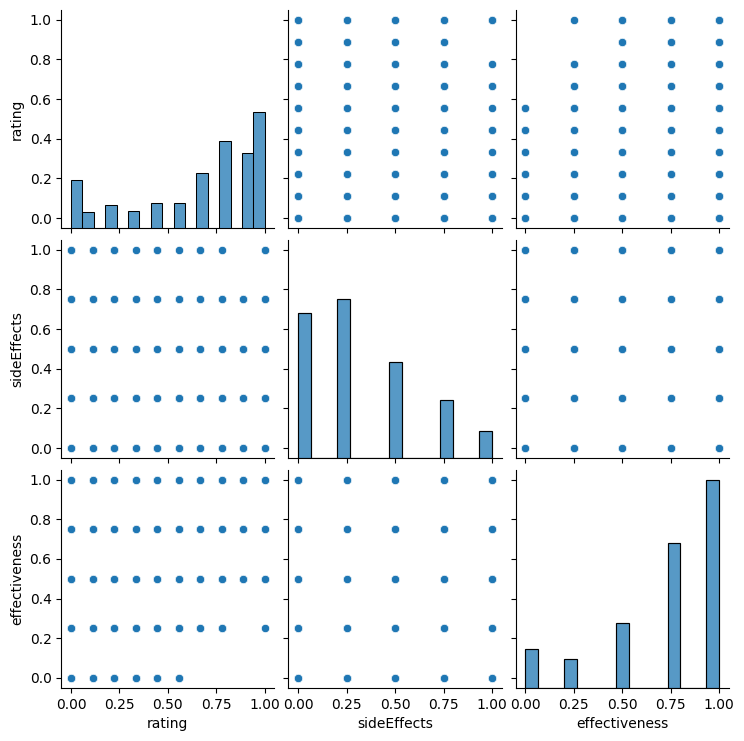

In [13]:
sns.pairplot(X)

In [14]:
X.duplicated().mean() # Proporción de filas repetidas

0.9433537174122948

*Ojo: como las tres variables solo toman unos pocos valores (10 × 5 × 5 = 250 combinaciones posibles), el 94% de las filas están repetidas y los scatter plots se ven como una rejilla: cada punto puede representar a muchos medicamentos.*

*Del gráfico de arriba podemos observar que los medicamentos con poca efectividad o con muchos efectos secundarios, así como los que tienen poco rating, los hay en menor cantidad que sus contrapartes; esto nos indica que, en general, hay más medicamentos positivos que defectuosos. Por otro lado, no se ve una clusterización clara en 2D, es decir, para pares de features. Podemos probar algo como:*

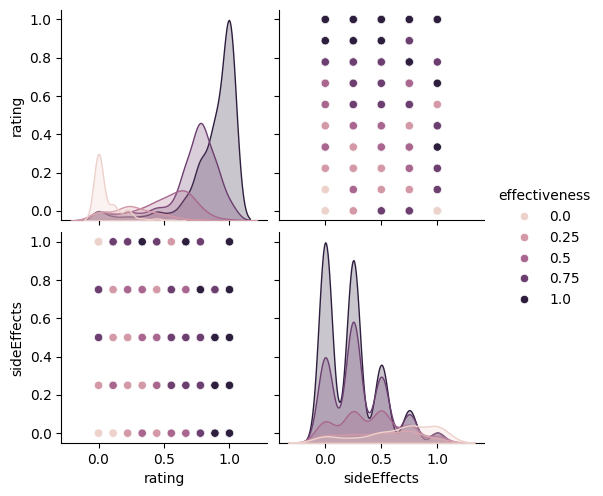

In [15]:
sns.pairplot(X, hue = "effectiveness")

*Tampoco se ve especialmente bien, pero si te fijas en el gráfico de la esquina superior derecha, los colores tienden a ser más oscuros a medida que aumenta el rating y también a medida que aumenta el nivel de sideEffects, lo que habla de una relación trivariante que sí puede manifestarse en la existencia de clústeres. En la figura de abajo se sugieren dos posibles agrupaciones de 2 o 3 clústeres visuales que no tienen por qué ser los que encuentre el modelo, pero que podríamos esperar.*

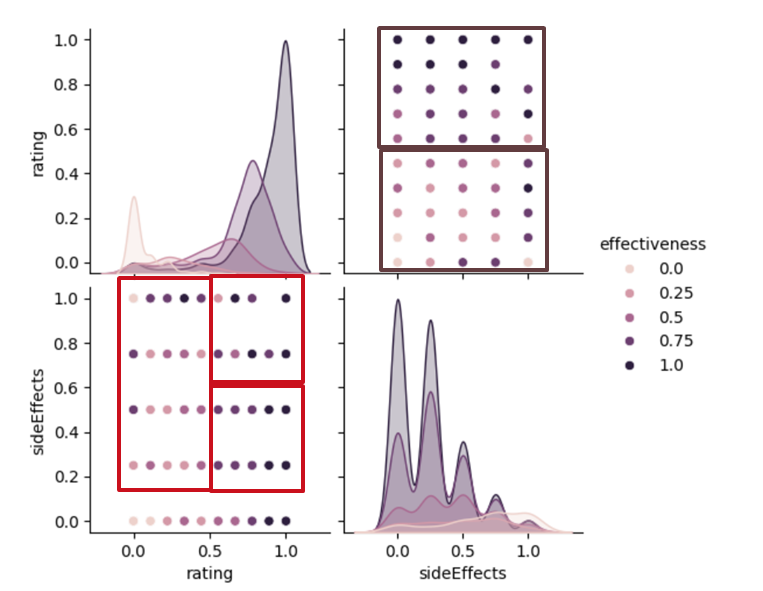

### Ejercicio 6: Obtención de K, método del codo

Evalúa diferentes valores de K y escoge uno a partir del método del codo/elbow de inercia.

In [16]:
# Vamos a probar con diferentes valores de k para ver cuál es el mejor según sus inercias y el método del codo
ks = []
inertias = []

for k in range(1, 10):
    clustering = KMeans(n_clusters = k, n_init = 10, random_state = 42)
    clustering.fit(X)
    inertias.append(clustering.inertia_)
    ks.append(k)

In [17]:
# Dataframe con las inercias
df_inertias = pd.DataFrame({'k': ks, 'inertia': inertias})
df_inertias

,k,inertia
0,1,893.992575
1,2,395.471897
2,3,299.907623
3,4,237.358562
4,5,188.356884
5,6,153.959304
6,7,134.483035
7,8,118.130117
8,9,104.309346


In [18]:
# Observamos cuánto varían las inercias de una k a otra
df_inertias['diff'] = df_inertias['inertia'] - df_inertias['inertia'].shift(1)
df_inertias

,k,inertia,diff
0,1,893.992575,NaN
1,2,395.471897,-498.520678
2,3,299.907623,-95.564274
3,4,237.358562,-62.549061
4,5,188.356884,-49.001677
5,6,153.959304,-34.397581
6,7,134.483035,-19.476269
7,8,118.130117,-16.352918
8,9,104.309346,-13.820772


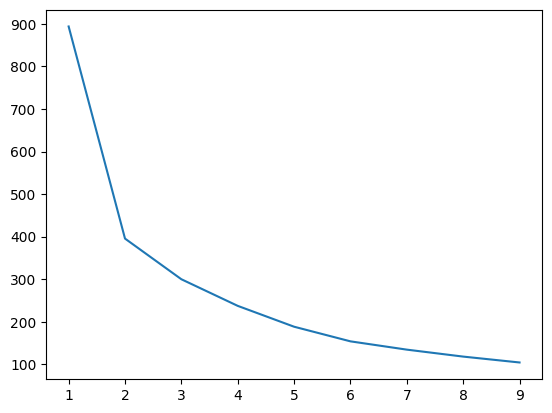

In [19]:
# Plot de las inercias incluyendo el paso de 1 a 2 grupos
plt.plot(ks, inertias);

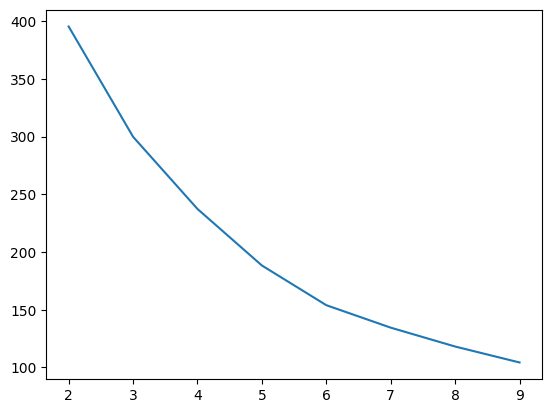

In [20]:
# Plot de las inercias sin el paso de 1 a 2 grupos
plt.plot(ks[1::], inertias[1::]);

*Tanto en los valores del dataframe como en la gráfica del codo, observamos que el mayor cambio se produce entre k=1 (todo en un grupo) y k=2 (dos grupos), y luego hay otro cambio apreciable entre 2 y 3. El codo podría estar en $K=2$ o $K=3$, pero con cierta duda, porque después la inercia sigue bajando de forma bastante gradual. Para confirmarlo acudiremos al score de silueta en el siguiente ejercicio.*

### Ejercicio 7: Obtención de K, Score de Silueta

Comprueba el ajuste de k obteniendo el k que maximiza el score de silueta y pinta un gráfico de la evolución de dicho score con k. Usa los valores de k que hayas probado en el ejercicio anterior.

In [21]:
#Calculamos el silhouette score para cada k
ks = []
sil_scores = []

for k in range(2, 10): 
    clustering = KMeans(n_clusters = k, n_init = 10, random_state = 42)
    clustering.fit(X)

    sil_scores.append(silhouette_score(X, clustering.labels_))
    ks.append(k)

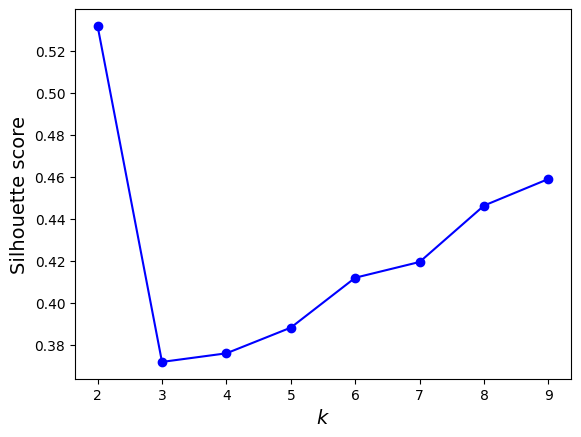

In [22]:
# Graficamos el silhouette score para cada k
plt.plot(ks, sil_scores, "bo-");
plt.xlabel("$k$", fontsize=14);
plt.ylabel("Silhouette score", fontsize=14);

*Normalmente nos interesará quedarnos con el silhouette score más alto, que aquí se obtiene claramente con k=2 (0,53): hay 2 grupos bien diferenciados. Para k=3, 4 y 5 queda bastante más bajo y muy parecido entre ellos (entre 0,37 y 0,39). Aun así, podríamos considerar algún k mayor si tuviera sentido para el negocio. Para terminar, acudamos al diagrama de silueta.*

### Ejercicio 8: Obtención de K, diagrama de silueta

Para completar el estudio de k, muestra el diagrama de silueta para k=2,3,4,5 y decide con estos datos y los anteriores el valor de k a probar. NOTA: En la realidad, podríamos probar perfectamente k=2 y k=3 y luego que "Negocio" decidiera cuál le es más útil; aquí lo completamos para practicar todo lo aprendido.

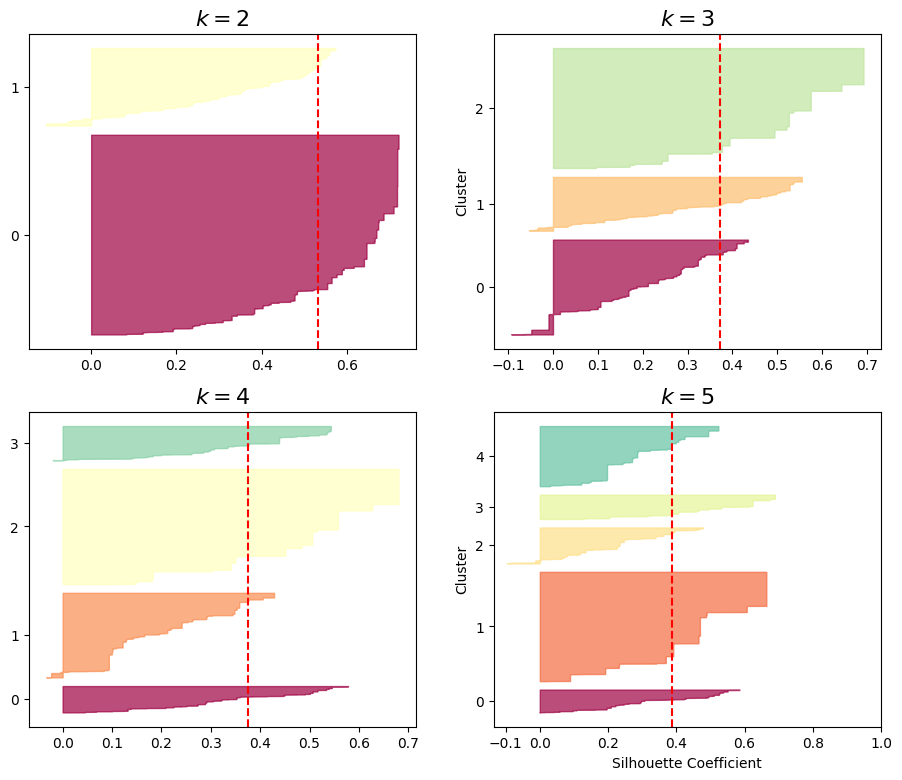

In [23]:

from matplotlib.ticker import FixedLocator, FixedFormatter

'''
La anchura de cada cuchillo representa el número de muestras por cluster. Están ordenadas
por su coeficiente de silueta, por eso tienen esa forma de cuchillo. Cuanta más caída tenga,
más disperso es el coeficiente de las muestras de ese cluster.
Deberían estar todos los clusters por encima de la media.
Hay algunas líneas hacia la izquierda porque el coeficiente es negativo: puntos asignados al cluster erróneo.
'''
plt.figure(figsize=(11, 9))

for k in (2, 3, 4, 5):
    plt.subplot(2, 2, k - 1)
    clustering = KMeans(n_clusters = k, n_init = 10, random_state = 42)
    clustering.fit(X)
    y_pred = clustering.labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = matplotlib.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")
    
    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=True)

    plt.axvline(x=sil_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)


plt.show()

*En los cuatro casos todos los clústeres tienen instancias por encima del score medio, así que el diagrama no descarta ningún k. Lo que sí vemos es que con $K=2$ el score medio es mucho más alto, aunque el clúster pequeño tiene algunos coeficientes negativos (instancias en la frontera). Con $K=3$ aparece un clúster intermedio con muchos coeficientes negativos (alrededor de un 20% de sus instancias), señal de que su frontera con los otros dos no está clara; a cambio, reparte las instancias de forma más uniforme. Veredicto: nos quedamos con $K=2$, el de mayor score de silueta, y probaremos también $K=3$ por si resultara más útil para el negocio.*

### Ejercicio 9

En general, una diferencia entre el proceso de construcción de un modelo no supervisado y un supervisado es que el ajuste de algunos hiperparámetros (como el número de clústeres) es anterior a la construcción del modelo. Por eso, construye un K-Means para el valor (o valores) de K escogidos.

*Ya tenemos nuestro número óptimo de clústeres, así que procedemos a generar nuestro K-Means para luego etiquetar.*

In [24]:
#KMeans con k = 2
clustering_k2 = KMeans(n_clusters = 2, n_init = 10, random_state = 42)
clustering_k2.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 3)","[[0.8

### Ejercicio 10

Vamos a comprobar resultados, analizando los valores medios y distribución de cada uno de los clústeres para el k óptimo. Si tuvieras más de un posible valor de k a probar, analiza aquí el de mayor score de silueta. Y utiliza el siguiente ejercicio para el otro. Además de hacer un describe de las features por clúster, píntalos con un pairplot considerando sideEffects y rating como x e y (o viceversa) y el clúster como hue (color). Compara el resultado con los clústeres sugeridos en el ejercicio 5.

*El score de silueta más alto nos lo dio K=2.*

In [25]:
# Trabajamos sobre una copia para no añadir columnas a X (lo volveremos a usar para k = 3)
X_k2 = X.copy()
X_k2['cluster'] = clustering_k2.labels_ # Cluster asignado a cada observación
X_k2.head()

,rating,sideEffects,effectiveness,cluster
0,0.333333,0.25,1.00,0
1,0.000000,0.75,1.00,1
2,1.000000,0.00,1.00,0
3,0.222222,0.25,0.25,1
4,0.111111,0.75,0.25,1


*Ya tenemos nuestras etiquetas generadas por K-Means; vamos a mirar un poco cómo agrupó los registros:*

In [26]:
# Cuántos elementos hay en cada cluster
X_k2['cluster'].value_counts(normalize = True)

cluster
0    0.720309
1    0.279691
Name: proportion, dtype: float64

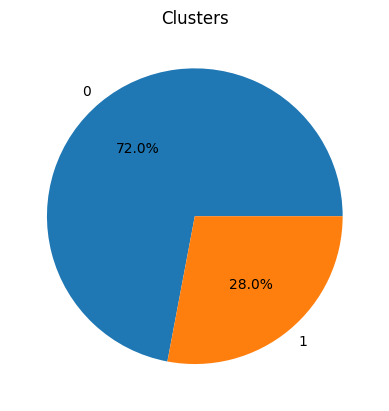

In [27]:
# Graficamos la cantidad de elementos en cada cluster
proporciones = X_k2['cluster'].value_counts(normalize = True)
plt.pie(proporciones, autopct = '%1.1f%%', labels = proporciones.index)
plt.title('Clusters');

*Hay muchos más medicamentos en un clúster (72%) que en el otro (28%). Vamos a analizar las estadísticas de cada grupo:*

In [28]:
X_k2.groupby('cluster').describe()

rating                                                              \
          count      mean       std  min       25%       50%       75%  max   
cluster                                                                       
0        2238.0  0.842369  0.146383  0.0  0.777778  0.888889  1.000000  1.0   
1         869.0  0.216596  0.208818  0.0  0.000000  0.222222  0.333333  1.0   

        sideEffects            ...            effectiveness            \
              count      mean  ...   75%  max         count      mean   
cluster                        ...                                      
0            2238.0  0.209674  ...  0.25  1.0        2238.0  0.868409   
1             869.0  0.626295  ...  0.75  1.0         869.0  0.387514   

                                              
              std   min   25%  50%  75%  max  
cluster                                       
0        0.164449  0.25  0.75  1.0  1.0  1.0  
1        0.319656  0.00  0.00  0.5  0.5  1.0  

[2 rows x 24 columns]

*Si observamos las estadísticas de cada columna por grupo, vemos que el clúster mayoritario tiene un rating y una efectividad medios mucho más altos y menos efectos secundarios que el otro: son medicamentos que en general funcionan bien frente a los que no. Vamos a etiquetar estos grupos como "Good" y "Bad". Fíjate en que asignamos las etiquetas según el rating medio de cada clúster, porque el número que K-Means da a cada uno es arbitrario.*

In [29]:
rating_medio = X_k2.groupby('cluster')['rating'].mean()
cluster_map = {rating_medio.idxmax(): 'Good', rating_medio.idxmin(): 'Bad'}
cluster_map

{0: 'Good', 1: 'Bad'}

In [30]:
X_k2['Label'] = X_k2['cluster'].map(cluster_map)
X_k2.head()

,rating,sideEffects,effectiveness,cluster,Label
0,0.333333,0.25,1.00,0,Good
1,0.000000,0.75,1.00,1,Bad
2,1.000000,0.00,1.00,0,Good
3,0.222222,0.25,0.25,1,Bad
4,0.111111,0.75,0.25,1,Bad


*Y ahora mostramos el pairplot y comparamos:*

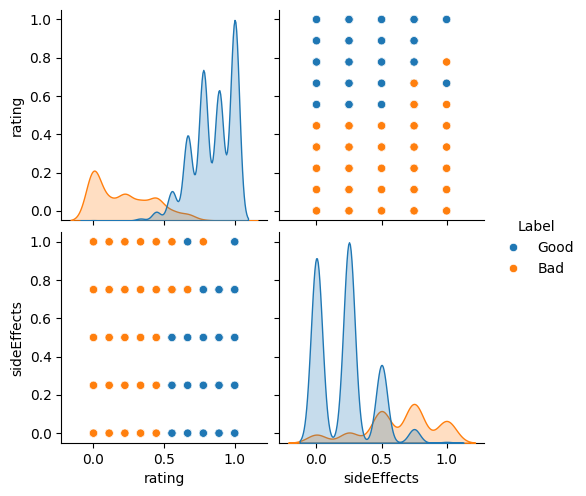

In [31]:
# Podemos ver la distribución de los clusters en el espacio de las variables
sns.pairplot(data = X_k2[['rating', 'sideEffects', 'Label']], hue = 'Label');

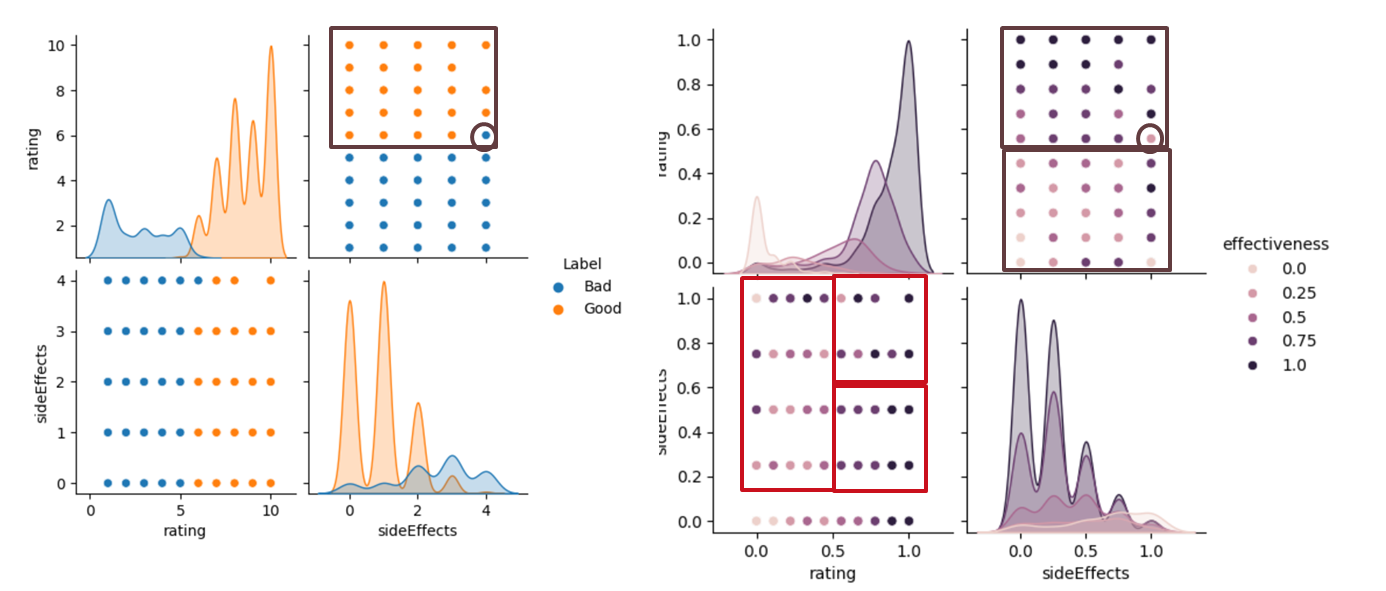

*Observa que son muy similares a los sugeridos en el ejercicio 5, e incluso mejores en la captura de algún punto extremo, como el indicado en la figura.*

*En este ejercicio lo bonito es ver que el clustering ha encontrado unas agrupaciones con bastante sentido, aunque no siempre tiene por qué ser así (ni lo será).*


### Ejercicio 11, EXTRA: Más valores de K

Repite el análisis del ejercicio 10 para un K diferente pero que consideres que tiene sentido aplicar.

In [32]:
# KMeans con k = 3
clustering_k3 = KMeans(n_clusters = 3, n_init = 10, random_state = 42)
clustering_k3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[[0.6

In [33]:
X_k3 = X.copy()
X_k3['cluster'] = clustering_k3.labels_ # Cluster asignado a cada observación
X_k3.head()

,rating,sideEffects,effectiveness,cluster
0,0.333333,0.25,1.00,0
1,0.000000,0.75,1.00,1
2,1.000000,0.00,1.00,2
3,0.222222,0.25,0.25,1
4,0.111111,0.75,0.25,1


In [34]:
X_k3['cluster'].value_counts(normalize = True)

cluster
2    0.446733
0    0.353074
1    0.200193
Name: proportion, dtype: float64

*Ahora la distribución entre clústeres está más repartida (45%, 35% y 20%), como ya veíamos en el diagrama de silueta.*

In [35]:
X_k3.groupby("cluster").describe()

rating                                                              \
          count      mean       std       min       25%       50%       75%   
cluster                                                                       
0        1097.0  0.652993  0.166477  0.000000  0.555556  0.666667  0.777778   
1         622.0  0.122544  0.142220  0.000000  0.000000  0.111111  0.222222   
2        1388.0  0.922831  0.095026  0.444444  0.888889  1.000000  1.000000   

                  sideEffects            ...            effectiveness  \
              max       count      mean  ...   75%  max         count   
cluster                                  ...                            
0        1.000000      1097.0  0.406791  ...  0.50  1.0        1097.0   
1        0.555556       622.0  0.664389  ...  1.00  1.0         622.0   
2        1.000000      1388.0  0.110951  ...  0.25  0.5        1388.0   

                                                         
             mean       std   min   25%   50%  75%  max  
cluster                                                  
0        0.736098  0.195992  0.25  0.50  0.75  1.0  1.0  
1        0.290595  0.301065  0.00  0.00  0.25  0.5  1.0  
2        0.930836  0.118526  0.50  0.75  1.00  1.0  1.0  

[3 rows x 24 columns]

*Con K=3 aparece una especie de "grado" o "scoring" de valor: un clúster con los mayores valores de rating y efectividad y menos efectos secundarios, otro intermedio y otro con los peores valores.*

In [36]:
# Ordenamos los clusters de mayor a menor rating medio para asignar las etiquetas
orden = X_k3.groupby('cluster')['rating'].mean().sort_values(ascending = False).index
cluster_map = dict(zip(orden, ['Very Good', 'Good', 'Bad']))

X_k3['Label'] = X_k3['cluster'].map(cluster_map)
cluster_map

{2: 'Very Good', 0: 'Good', 1: 'Bad'}

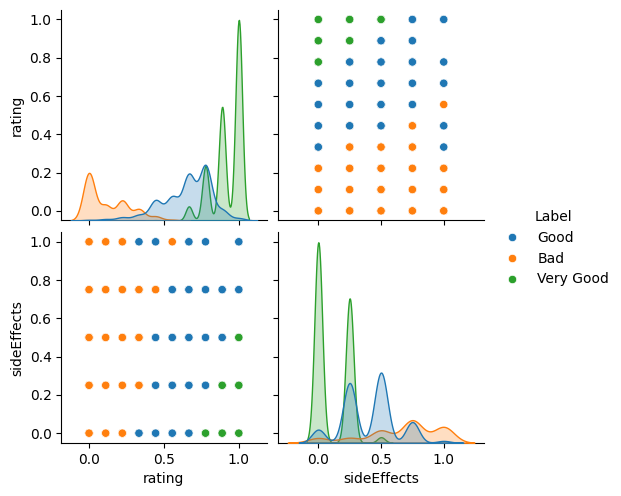

In [37]:
sns.pairplot(data = X_k3[["Label", "rating", "sideEffects"]], hue = "Label");

*Comparando con el pairplot del ejercicio 5, nos daremos cuenta de que los clústeres no tienen por qué tener formas regulares, e incluso que K=3 es una buena agrupación y con sentido:*

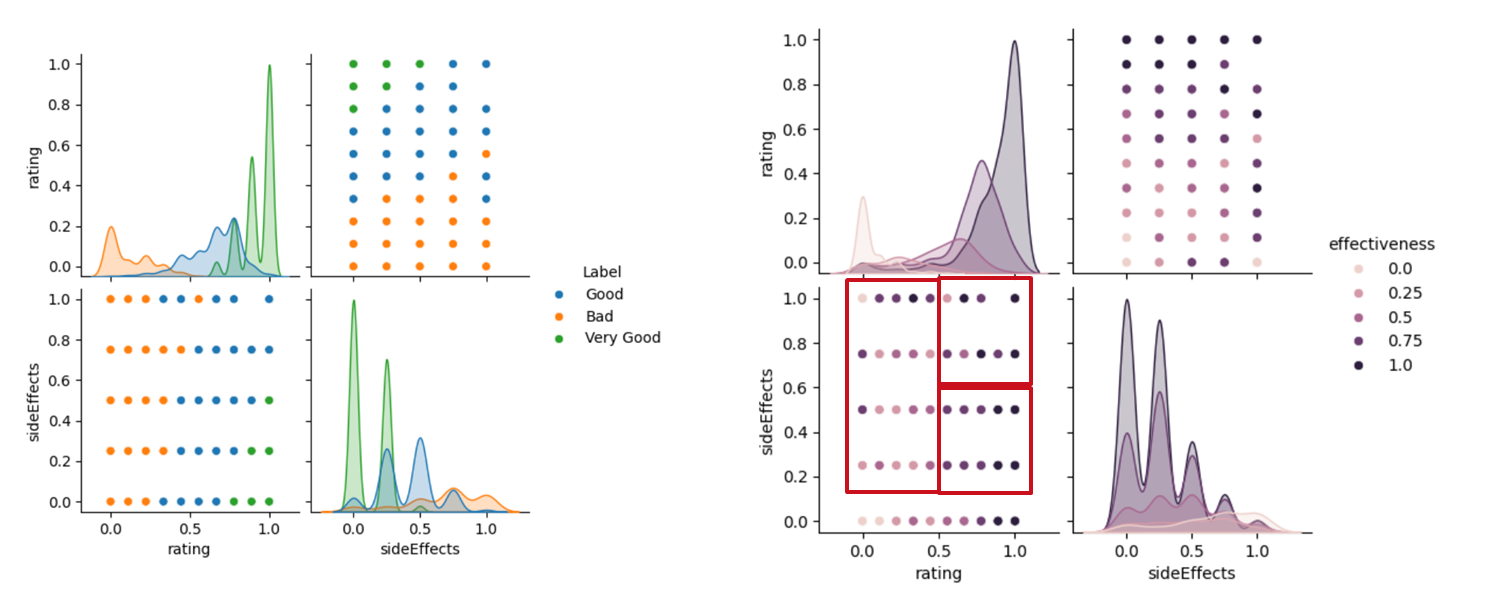

*¿Cuál te parece mejor?*